In [4]:
##### Figure 4: % of global capital, labor, and production in priority regions

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [5]:
##### LOAD DATA

ROOT = Path.cwd().parent

summary_df = pd.read_csv(ROOT / "Results/30x30/global_exposure_summary.csv")

FIG_DIR = ROOT / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
##### STYLING

COLORS = {
    "Capital": "#2F7C87",
    "Labor": "#C96A3B",
    "Production": "#6B7280",
    "Area": "#8E5B9F",
}

STATUS_COLORS = {
    "Additional priority": "#D9D9D9",
    "Already in PA": "#595959",
}

TITLE_FS = 8   # subplot titles
LABEL_FS = 7   # axis and legend labels
TICK_FS = 6    # tick labels

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica"],
    "font.size": TICK_FS,
    "axes.titlesize": TITLE_FS,
    "axes.labelsize": LABEL_FS,
    "xtick.labelsize": TICK_FS,
    "ytick.labelsize": TICK_FS,
    "legend.fontsize": LABEL_FS,
})

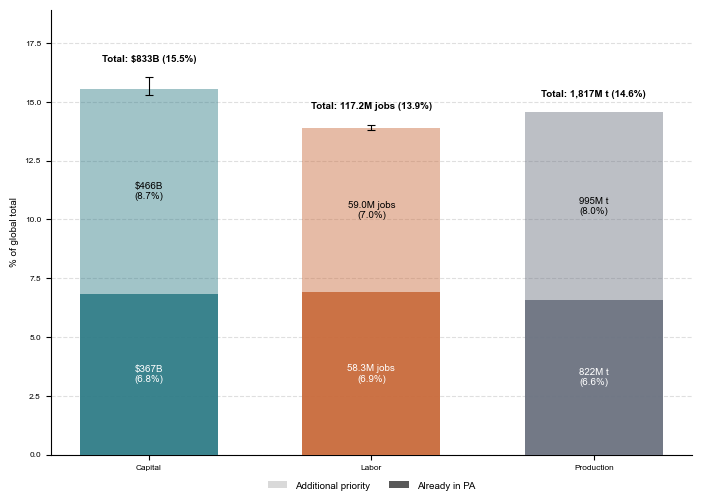

In [7]:
##### FIGURE 4

variables = ["Capital", "Labor", "Production"]
x = np.arange(len(variables))
width = 0.62

# format value labels
def fmt_value(variable, value):
    if variable == "Capital":
        return f"${value / 1e9:,.0f}B" if value >= 1e9 else f"${value / 1e6:,.0f}M"
    elif variable == "Labor":
        return f"{value / 1e6:,.1f}M jobs" if value >= 1e6 else f"{value / 1e3:,.0f}K jobs"
    else:
        return f"{value / 1e6:,.0f}M t" if value >= 1e6 else f"{value / 1e3:,.0f}K t"

fig, ax = plt.subplots(figsize=(7, 5))

for i, variable in enumerate(variables):
    row = summary_df.loc[summary_df["Variable"] == variable].iloc[0]

    pct_already = row["Pct_already"]
    pct_additional = row["Pct_additional"]
    abs_already = row["Already_in_PA"]
    abs_additional = row["Additional_priority"]

    # darker shade = already PA; lighter shade = additional priority
    ax.bar(i, pct_already, width, color=COLORS[variable], alpha=0.95, zorder=3)
    ax.bar(
        i, pct_additional, width, bottom=pct_already,
        color=COLORS[variable], alpha=0.45, zorder=3,
    )

    # existing PA label
    if pct_already >= 3:
        ax.text(
            i, pct_already / 2,
            f"{fmt_value(variable, abs_already)}\n({pct_already:.1f}%)",
            ha="center", va="center", fontsize=LABEL_FS, color="white", zorder=4,
        )
    else:
        ax.text(
            i + width / 2 + 0.03, pct_already / 2,
            f"{fmt_value(variable, abs_already)} ({pct_already:.1f}%)",
            ha="left", va="center", fontsize=LABEL_FS, zorder=4,
        )

    # new/additional PA label
    if pct_additional >= 3:
        ax.text(
            i, pct_already + pct_additional / 2,
            f"{fmt_value(variable, abs_additional)}\n({pct_additional:.1f}%)",
            ha="center", va="center", fontsize=LABEL_FS, color="black", zorder=4,
        )
    else:
        ax.text(
            i + width / 2 + 0.03, pct_already + pct_additional / 2,
            f"{fmt_value(variable, abs_additional)} ({pct_additional:.1f}%)",
            ha="left", va="center", fontsize=LABEL_FS, zorder=4,
        )

    # error bar on total (p10-p90)
    total = row["Pct_total"]
    lo, hi = row["Pct_total_p10"], row["Pct_total_p90"]
    if hi != total or lo != total:
        ax.errorbar(
            i, total,
            yerr=[[max(total - lo, 0)], [max(hi - total, 0)]],
            fmt="none", ecolor="black", elinewidth=0.8, capsize=3, capthick=0.8,
            zorder=5,
        )

    # total label
    ax.text(
        i, max(total, hi) + 0.6,
        f"Total: {fmt_value(variable, row['Total_priority'])} ({total:.1f}%)",
        ha="center", va="bottom", fontsize=LABEL_FS, fontweight="bold",
    )

ax.set_xticks(x)
ax.set_xticklabels(variables)
ax.set_ylabel("% of global total")

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)
ax.set_ylim(0, summary_df[["Pct_total", "Pct_total_p90"]].max().max() * 1.18)

legend_elements = [
    Patch(facecolor=STATUS_COLORS["Additional priority"], label="Additional priority"),
    Patch(facecolor=STATUS_COLORS["Already in PA"], label="Already in PA"),
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=2,
    frameon=False,
)

plt.tight_layout()
plt.savefig(FIG_DIR / "Figure_4_global_exposure.tiff", dpi=300, bbox_inches="tight")
plt.show()